<a href="https://colab.research.google.com/github/sanya-6976/loan-approval-ml-project/blob/main/loan_approval_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv"
df = pd.read_csv(url)

print("shape:" , df.shape)
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n--- Target Distribution (%) ---")
print(df['Loan_Status'].value_counts(normalize=True)*100)



shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



--- Missing Values ---
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

--- Target Distribution (%) ---
Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


NOTE :- LOAN_ID IS THE COLUMN
TO BE DROPPED.


# **EDA & Data Leakage-Free Preprocessing**

     Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0      Male      No          0      Graduate            No             5849   
1      Male     Yes          1      Graduate            No             4583   
2      Male     Yes          0      Graduate           Yes             3000   
3      Male     Yes          0  Not Graduate            No             2583   
4      Male      No          0      Graduate            No             6000   
..      ...     ...        ...           ...           ...              ...   
609  Female      No          0      Graduate            No             2900   
610    Male     Yes         3+      Graduate            No             4106   
611    Male     Yes          1      Graduate            No             8072   
612    Male     Yes          2      Graduate            No             7583   
613  Female      No          0      Graduate           Yes             4583   

     CoapplicantIncome  LoanAmount  Loan_Amount_Ter

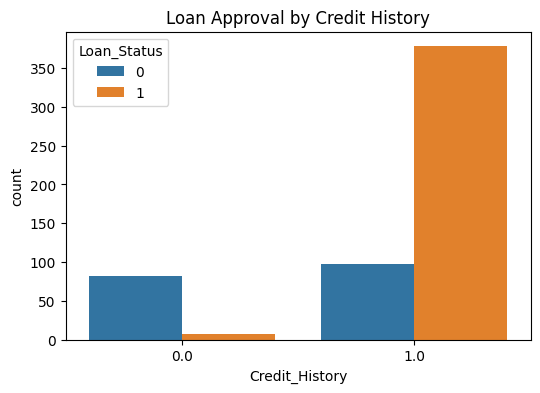

     Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
154    Male      No          0      Graduate            No             3254   
239    Male     Yes          1      Graduate            No             3315   
448    Male     Yes          2      Graduate            No             3340   
471    Male     Yes          1  Not Graduate            No             2653   
273    Male     Yes          0      Graduate            No             2620   
..      ...     ...        ...           ...           ...              ...   
222    Male      No          0      Graduate            No             2971   
349    Male     Yes          0      Graduate            No             2625   
26     Male     Yes          0      Graduate            No             2799   
96   Female     Yes          0      Graduate            No             2484   
354  Female     Yes          0      Graduate            No             2423   

     CoapplicantIncome  LoanAmount  Loan_Amount_Ter

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# DROP LOAN_ID COLUMN AND ENCODE LOAN STATUS AS (Y -> 1, N -> 0)
df_clean = df.drop(columns=["Loan_ID"]).copy()
df_clean["Loan_Status"] = df_clean["Loan_Status"].map({'Y': 1, 'N': 0})
print(df_clean)

plt.figure(figsize=(6 , 4))
sns.countplot(data = df_clean , x ="Credit_History" , hue = 'Loan_Status')
plt.title('Loan Approval by Credit History')
plt.show()

X = df_clean.drop(columns=["Loan_Status"])
y = df_clean['Loan_Status']

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state=42 , stratify=y)
print(X_train)
print(X_test)
print(y_train)
print(y_test)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

# **Preprocessing Pipeline & Baseline Decision Tree**

**"We chose Decision Tree as our baseline because loan approval follows non-linear, rule-based thresholds on tabular data without needing feature scaling. Plus, an unpruned tree immediately exposes variance and overfitting on this small dataset, giving us a clear benchmark to justify moving to ensembles like Random Forest and Gradient Boosting.**

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Corrected column names (removed extra 'o' in Applicant and Coapplicant)
num_col = ['ApplicantIncome' , 'CoapplicantIncome' , 'LoanAmount' , 'Loan_Amount_Term' , 'Credit_History']
cat_col =['Gender' , 'Married' , 'Education' , 'Self_Employed' ,'Property_Area']


#preprocessing pipelines
num_transformer = SimpleImputer(strategy = 'median')
cat_transformer = Pipeline(steps = [
    ('imputer' , SimpleImputer(strategy='most_frequent')) ,
('onehot' , OneHotEncoder(handle_unknown ='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num' , num_transformer , num_col) ,
    ('cat' , cat_transformer , cat_col)
])

dt_pipeline = Pipeline(steps=[
    ('preprocessor' , preprocessor) ,
    ('classifier' , DecisionTreeClassifier(random_state = 42))
])
dt_pipeline.fit(X_train, y_train)


train_pred = dt_pipeline.predict(X_train)
test_pred = dt_pipeline.predict(X_test)
test_proba = dt_pipeline.predict_proba(X_test)[:, 1]

print(f"Train Accuracy : {accuracy_score(y_train, train_pred):.4f}")
print(f"Test Accuracy  : {accuracy_score(y_test, test_pred):.4f}")
print(f"Test F1-Score  : {f1_score(y_test, test_pred):.4f}")
print(f"Test ROC-AUC   : {roc_auc_score(y_test, test_proba):.4f}")

Train Accuracy : 1.0000
Test Accuracy  : 0.7154
Test F1-Score  : 0.7879
Test ROC-AUC   : 0.6850
